# Part 5 Daily Sales Forecasting and Model Evaluation

After exploring the sales patterns, I wanted to see whether historical data could be used to predict Melt Gelato’s daily revenue.

I compared three forecasting approaches to understand which one performed best. The aim was to develop a practical forecasting method that could eventually help the business prepare stock and plan staffing more effectively.

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display

HERE = Path.cwd()
ROOT = HERE.parent if HERE.name == "notebooks" else HERE
RAW_DIR = ROOT / "data" / "raw"
PROCESSED_DIR = ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)


In [2]:
sales_weather = pd.read_csv(PROCESSED_DIR / "sales_weather.csv", parse_dates=['sale_date'])
print("Loaded sales_weather:", sales_weather.shape)

Loaded sales_weather: (360, 13)


## 5.1 Chronological split and calendar features

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt

sales_weather = sales_weather.sort_values("sale_date").reset_index(drop=True)
assert sales_weather["sale_date"].is_unique
TARGET = "refund_adjusted_gross_eur"
assert sales_weather[TARGET].notna().all()
for col in ["temp_mean_c", "rain_mm", "sunshine_hours"]:
    assert sales_weather[col].notna().all(), f"Missing weather variable: {col}"

model_data = sales_weather.copy()
model_data["weekday"] = model_data["sale_date"].dt.dayofweek.astype(str)
model_data["month"] = model_data["sale_date"].dt.month.astype(str)
model_data["day_of_year"] = model_data["sale_date"].dt.dayofyear
model_data["sin_annual"] = np.sin(2 * np.pi * model_data["day_of_year"] / 365.25)
model_data["cos_annual"] = np.cos(2 * np.pi * model_data["day_of_year"] / 365.25)


prev_week = model_data[["sale_date", TARGET]].copy()
prev_week["sale_date"] += pd.Timedelta(days=7)
prev_week = prev_week.rename(columns={TARGET: "last_week_same_day"})
model_data = model_data.merge(prev_week, on="sale_date", how="left", validate="one_to_one")

split = int(len(model_data) * 0.80)
train, test = model_data.iloc[:split].copy(), model_data.iloc[split:].copy()
print("Training:", train.sale_date.min().date(), "to", train.sale_date.max().date(), len(train))
print("Testing:", test.sale_date.min().date(), "to", test.sale_date.max().date(), len(test))
print("Missing exact 7-day baseline in test:", test.last_week_same_day.isna().sum())

Training: 2024-12-01 to 2025-09-19 288
Testing: 2025-09-20 to 2025-11-30 72
Missing exact 7-day baseline in test: 0


### Preparing the Forecasting Data

I prepared the daily sales data for forecasting using refund-adjusted gross revenue as the target variable.

I also created calendar-related features to capture recurring patterns in demand, such as differences between weekdays and weekends.

The dataset was divided chronologically into 288 training days and 72 testing days. I used this approach instead of a random split because the model should be evaluated on observations that occur after its training period.

## 5.2 Fit models on training data only
- Ridge regression regularises correlated features. 
- One-hot encoders learn categories only from the training period.

In [4]:
categorical = ["weekday", "month"]
calendar_numeric = ["sin_annual", "cos_annual"]
weather_numeric = ["temp_mean_c", "rain_mm", "sunshine_hours"]

def make_model(numeric):
    prep = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
        ("num", Pipeline([("impute", SimpleImputer(strategy="median"))]), numeric)
    ])
    return Pipeline([("prep", prep), ("ridge", Ridge(alpha=10.0))])

calendar_model = make_model(calendar_numeric)
weather_model = make_model(calendar_numeric + weather_numeric)
calendar_model.fit(train[categorical + calendar_numeric], train[TARGET])
weather_model.fit(train[categorical + calendar_numeric + weather_numeric], train[TARGET])

comparison = test.loc[test.last_week_same_day.notna(), ["sale_date", TARGET, "last_week_same_day"]].copy()
comparison["Seasonal naive (t-7)"] = comparison["last_week_same_day"]
comparison["Calendar Ridge"] = calendar_model.predict(test.loc[comparison.index, categorical + calendar_numeric])
comparison["Calendar + observed weather Ridge"] = weather_model.predict(test.loc[comparison.index, categorical + calendar_numeric + weather_numeric])
print("Comparable test dates:",len(comparison))

Comparable test dates: 72


### Seasonal Naïve Forecast

I started with a simple baseline model that predicts daily revenue using the revenue recorded seven days earlier.

This approach assumes that sales patterns repeat from one week to the next.

I used it as a reference point to understand whether the more advanced forecasting models could provide better predictions.

### Calendar Ridge Regression

Next, I trained a Ridge Regression model using calendar-related information.

This model was selected because the earlier analysis showed clear differences in sales across weekdays and other calendar periods.

I wanted to see whether these recurring patterns could help predict daily revenue more accurately than the seasonal baseline.

## 5.3 Holdout accuracy
- MAE and RMSE are in euros per day. 
- WAPE is total absolute error divided by total actual revenue. it is not a per-day percentage error.

In [5]:
def scores(y, pred):
    y = np.asarray(y, dtype=float)
    pred = np.asarray(pred, dtype=float)
    return {"MAE_eur": mean_absolute_error(y, pred),
            "RMSE_eur": np.sqrt(mean_squared_error(y, pred)),
            "WAPE_pct": 100 * np.abs(y - pred).sum() / np.abs(y).sum()}

rows = []
for name in ["Seasonal naive (t-7)", "Calendar Ridge", "Calendar + observed weather Ridge"]:
    rows.append({"model": name, **scores(comparison[TARGET], comparison[name])})
results = pd.DataFrame(rows).sort_values("MAE_eur")
display(results.round(2))
print("Best holdout MAE:", results.iloc[0]["model"])
print("Caution: model selection on this holdout can be optimistic; further rolling-origin validation is recommended.")

,model,MAE_eur,RMSE_eur,WAPE_pct
1,Calendar Ridge,153.61,204.62,12.74
2,Calendar + observed weather Ridge,181.29,226.92,15.03
0,Seasonal naive (t-7),227.08,300.88,18.83


Best holdout MAE: Calendar Ridge
Caution: model selection on this holdout can be optimistic; further rolling-origin validation is recommended.


 ### Visualising Forecasting Performance

I plotted the actual daily revenue alongside predictions from all three models to compare their performance during the testing period.

Calendar Ridge generally followed the overall sales pattern more closely, although differences remained during periods of unusually high or low demand.

This shows that forecasting can support operational planning, but predictions should still be reviewed alongside business knowledge and recent sales activity.

## 5.4 Plot holdout predictions

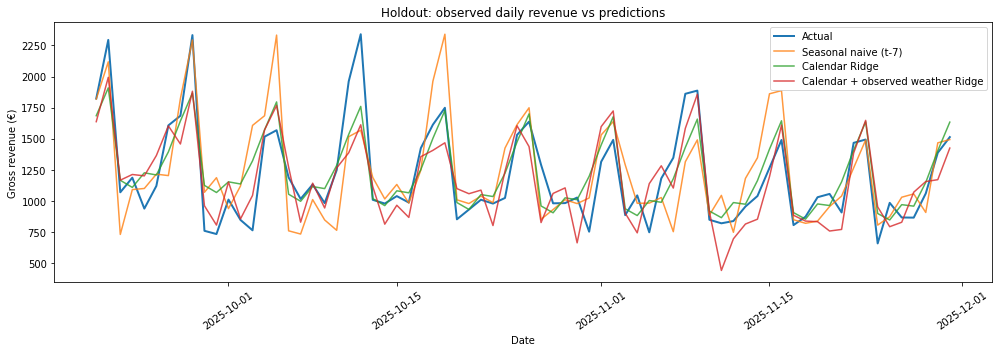

In [6]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(comparison.sale_date, comparison[TARGET], label="Actual", linewidth=2)
for name in ["Seasonal naive (t-7)", "Calendar Ridge", "Calendar + observed weather Ridge"]:
    ax.plot(comparison.sale_date, comparison[name], label=name, alpha=0.8)
ax.set(title="Holdout: observed daily revenue vs predictions", ylabel="Gross revenue (€)", xlabel="Date")
ax.legend()
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

## 5.5 Interpretation — executed results

The chronological split used **288 training days (1 Dec 2024–19 Sep 2025)** and **72 test days (20 Sep–30 Nov 2025)**. The prediction target was daily **refund-adjusted gross revenue**.

| Model | MAE €/day | RMSE €/day | WAPE |
|---|---:|---:|---:|
| **Calendar Ridge** | **153.61** | **204.62** | **12.74%** |
| Calendar + observed weather Ridge | 181.29 | 226.92 | 15.03% |
| Seasonal naïve (same weekday previous week) | 227.08 | 300.88 | 18.83% |

**Calendar Ridge was best on this holdout.** Its average absolute daily prediction error was approximately €154. Compared with the weekly naïve baseline, it reduced MAE by **€73.47 (32.4%)**. Adding observed weather worsened MAE by **€27.68 (18.0%)** relative to Calendar Ridge. Thus the significant weather associations found in Part 4 did **not** translate into better out-of-sample predictions on these dates.

**Limitations:** one holdout is insufficient to establish year-round superiority. The weather model uses actual weather observed during the test period, which would not be known in advance. Further rolling-origin validation, access to weather forecasts, and operational data would be needed before deployment. These errors cannot be directly converted into staffing or inventory savings.

In [7]:
comparison.to_csv(PROCESSED_DIR / "forecast_holdout_predictions.csv", index=False)
results.to_csv(PROCESSED_DIR / "forecast_model_comparison.csv", index=False)
print("Saved Part 5 outputs to data/processed/")

Saved Part 5 outputs to data/processed/
